# Mini-Project 1: UBOS District Population Forecaster

**Scenario.** A district planning unit wants 5-year population forecasts so it can plan primary-school classrooms.
We have 10 years (2015–2024) of population estimates, in **thousands of people**. The numbers are *illustrative*
(made up for the exercise), not official UBOS figures.

**How this notebook is organised.** The reusable code (classes and functions) lives in `src/population.py`.
This notebook imports it, runs each task in order, and explains the results.
Every task from the assignment has its own heading below.

In [1]:
# --- Imports: code we borrow ---------------------------------------------------

# statistics: Python's built-in module for mean, median, variance, stdev
import statistics

# numpy: fast maths on arrays of numbers ("np" is the usual nickname)
import numpy as np

# pandas: tables (DataFrames) - we use them to display results neatly
import pandas as pd

# matplotlib.pyplot: draws charts ("plt" is the usual nickname)
import matplotlib.pyplot as plt

# Our own code, written in src/population.py
from src.population import (
    DistrictPopulation,        # class that holds one district's data
    LinearTrendForecaster,     # model (a): straight line
    CAGRForecaster,            # model (b): constant % growth
    FibonacciRatioForecaster,  # model (c): the old Fibonacci method
    evaluate_models,           # trains + tests all models, returns a score table
    best_model_for,            # picks the model with the lowest test error
    extra_classrooms_needed,   # turns population growth into classrooms
    bootstrap_intervals,       # extension: 95% prediction intervals
)

SEED = 42                      # fixed "random seed" so every run gives the same numbers
TRAIN_END = 2021               # train on 2015-2021, test on 2022-2024
HORIZON = 5                    # forecast 5 years ahead (2025-2029)

# Chart colours (a colour-blind-friendly set) and a clean chart style
BLUE, ORANGE, AQUA, INK = "#2a78d6", "#eb6834", "#1baf7a", "#3b3a37"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100})

## Task 1 – The `DistrictPopulation` class

The class stores the years and populations as NumPy arrays and **validates** them (equal lengths, no negative values).
It has `__repr__` (what Python prints for the object) and `__len__` (so `len(district)` works).
We add two districts of our own: **Mbarara** and **Jinja** (illustrative numbers, in thousands).

In [2]:
years = list(range(2015, 2025))   # [2015, 2016, ..., 2024]

# Population in thousands for each district, 2015-2024 (illustrative)
raw_data = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso":  [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu":    [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480],
    "Mbarara": [ 470,  485,  500,  515,  530,  550,  565,  585,  600,  620],   # our choice
    "Jinja":   [ 480,  490,  500,  510,  520,  530,  545,  555,  565,  580],   # our choice
}

# Build one DistrictPopulation object per district and keep them in a dictionary
districts = {name: DistrictPopulation(name, years, values) for name, values in raw_data.items()}

for district in districts.values():
    print(district, "| number of years:", len(district))

DistrictPopulation('Kampala', 2015-2024, latest=1800k) | number of years: 10
DistrictPopulation('Wakiso', 2015-2024, latest=1670k) | number of years: 10
DistrictPopulation('Gulu', 2015-2024, latest=480k) | number of years: 10
DistrictPopulation('Mbarara', 2015-2024, latest=620k) | number of years: 10
DistrictPopulation('Jinja', 2015-2024, latest=580k) | number of years: 10


In [3]:
# Validation in action: these two bad inputs are rejected with a clear message.
# try/except lets us catch the error and print it instead of crashing the notebook.
for bad_values in ([100, 200], [100, -5, 120, 130, 140, 150, 160, 170, 180, 190]):
    try:
        DistrictPopulation("Bad district", years, bad_values)
    except ValueError as error:
        print("Rejected:", error)

Rejected: Bad district: 10 years but 2 population values
Rejected: Bad district: population cannot be negative


## Task 2 – Descriptive statistics: `statistics` vs NumPy

In [4]:
rows = []   # one row per district per method
for name, district in districts.items():
    rows.append({"district": name, "method": "statistics", **district.stats_with_statistics_module()})
    rows.append({"district": name, "method": "numpy (ddof=0)", **district.stats_with_numpy(ddof=0)})
    rows.append({"district": name, "method": "numpy (ddof=1)", **district.stats_with_numpy(ddof=1)})
# (**dictionary "unpacks" the mean/median/variance/std_dev keys into this row)

stats_table = pd.DataFrame(rows).set_index(["district", "method"])
stats_table.round(1)

mean  median  variance  std_dev
district method                                           
Kampala  statistics      1477.0  1460.0   42601.1    206.4
         numpy (ddof=0)  1477.0  1460.0   38341.0    195.8
         numpy (ddof=1)  1477.0  1460.0   42601.1    206.4
Wakiso   statistics      1280.0  1260.0   60066.7    245.1
         numpy (ddof=0)  1280.0  1260.0   54060.0    232.5
         numpy (ddof=1)  1280.0  1260.0   60066.7    245.1
Gulu     statistics       389.5   382.5    2885.8     53.7
         numpy (ddof=0)   389.5   382.5    2597.2     51.0
         numpy (ddof=1)   389.5   382.5    2885.8     53.7
Mbarara  statistics       542.0   540.0    2551.1     50.5
         numpy (ddof=0)   542.0   540.0    2296.0     47.9
         numpy (ddof=1)   542.0   540.0    2551.1     50.5
Jinja    statistics       527.5   525.0    1112.5     33.4
         numpy (ddof=0)   527.5   525.0    1001.2     31.6
         numpy (ddof=1)   527.5   525.0    1112.5     33.4

**Why do `statistics.variance` and `np.var` give different numbers?**

Variance is the average squared distance from the mean, but "average" can divide by two different things:

* `statistics.variance` treats the data as a **sample** from a bigger population and divides by **n − 1** (10 − 1 = 9 here).
  Dividing by a slightly smaller number makes the answer slightly bigger. This corrects for the fact that a sample
  usually *underestimates* the spread of the whole population (Bessel's correction).
* `np.var` by default treats the data as the **whole population** and divides by **n** (10).

The `ddof` argument ("delta degrees of freedom") tells NumPy to divide by **n − ddof**.
`np.var(x, ddof=1)` gives exactly the same answer as `statistics.variance(x)`, as the table shows.
The mean and median are the same for both methods, because they don't involve this division.

## Task 3 – Growth rates and CAGR

* **Year-on-year growth** = (this year − last year) ÷ last year × 100.
* **CAGR** (Compound Annual Growth Rate) = (last ÷ first)^(1 / years) − 1: the one steady rate that gets
  from the 2015 value to the 2024 value.

In [5]:
# Year-on-year growth (%) - one column per district, one row per year from 2016
growth_table = pd.DataFrame(
    {name: d.growth_rates() for name, d in districts.items()},
    index=years[1:],
)
growth_table.round(2)

,Kampala,Wakiso,Gulu,Mbarara,Jinja
2016,4.17,5.26,3.12,3.19,2.08
2017,4.00,7.00,4.55,3.09,2.04
2018,3.85,7.48,4.35,3.00,2.00
2019,5.19,6.09,4.17,2.91,1.96
2020,5.63,6.56,4.00,3.77,1.92
2021,5.33,6.92,5.13,2.73,2.83
2022,4.43,6.47,4.88,3.54,1.83
2023,4.24,6.08,5.81,2.56,1.80
2024,4.65,6.37,5.49,3.33,2.65


In [6]:
# CAGR for each district, as a percentage, fastest first
cagr_table = pd.Series({name: d.cagr() * 100 for name, d in districts.items()},
                       name="CAGR (% per year)").sort_values(ascending=False)
print(cagr_table.round(2))
print("\nFastest-growing in relative terms:", cagr_table.index[0])

Wakiso     6.47
Kampala    4.61
Gulu       4.61
Mbarara    3.13
Jinja      2.12
Name: CAGR (% per year), dtype: float64

Fastest-growing in relative terms: Wakiso


## Task 4 – Three forecasting models (inheritance)

All three models are **child classes** of an abstract parent class `Forecaster`, which defines the two methods every
model must have: `fit(years, values)` and `predict(horizon)`. The parent can't be used on its own. It's a template.

| Model | Idea |
|---|---|
| `LinearTrendForecaster` | straight line through the points (`np.polyfit`, degree 1) |
| `CAGRForecaster` | grow the last value by the same % every year |
| `FibonacciRatioForecaster` | multiply the last value by 1/1, 2/1, 3/2, 5/3, … (the previous cohort's method) |

A quick look at what each model predicts for Kampala after training on 2015–2021:

In [7]:
kampala = districts["Kampala"]
train_years, train_values, test_years, test_values = kampala.split(TRAIN_END)

for model in [LinearTrendForecaster(), CAGRForecaster(), FibonacciRatioForecaster()]:
    model.fit(train_years, train_values)
    guesses = model.predict(3)              # 3 test years: 2022, 2023, 2024
    print(f"{model.name:20s} predicts {np.round(guesses)}   (actual: {test_values})")

Linear trend         predicts [1623. 1686. 1749.]   (actual: [1650. 1720. 1800.])
Exponential (CAGR)   predicts [1654. 1732. 1813.]   (actual: [1650. 1720. 1800.])
Fibonacci ratio      predicts [1580. 3160. 4740.]   (actual: [1650. 1720. 1800.])


## Task 5 – Validate before forecasting

Each model is trained on **2015–2021** and tested on **2022–2024**, which it has never seen. We measure:

* **MAE**: average miss, in thousands of people.
* **RMSE**: like MAE but big misses count more.
* **MAPE**: average miss as a % of the real value (fair across big and small districts).

The best model per district is the one with the lowest RMSE (the top row of each table).

In [8]:
best_models = {}   # district name -> name of the best model
for name, district in districts.items():
    table = evaluate_models(district, TRAIN_END)
    best_models[name] = table.index[0]
    print(f"=== {name} ===")
    print(table.round(2).to_string(), "\n")   # .to_string() prints the whole table

print("Best model per district:", best_models)

=== Kampala ===
                        MAE     RMSE  MAPE (%)
model                                         
Exponential (CAGR)     9.62    10.39      0.55
Linear trend          37.62    38.97      2.17
Fibonacci ratio     1483.33  1890.51     83.77 

=== Wakiso ===
                        MAE     RMSE  MAPE (%)
model                                         
Exponential (CAGR)     6.80     8.05      0.42
Linear trend          49.40    52.37      3.09
Fibonacci ratio     1266.67  1604.39     77.62 

=== Gulu ===
                       MAE    RMSE  MAPE (%)
model                                       
Exponential (CAGR)    9.44   10.87      2.02
Linear trend         18.57   20.29      4.01
Fibonacci ratio     378.33  481.71     80.37 

=== Mbarara ===
                       MAE    RMSE  MAPE (%)
model                                       
Exponential (CAGR)    1.23    1.48      0.21
Linear trend          5.77    6.04      0.95
Fibonacci ratio     541.67  692.08     88.38 

=== Jinja ==

## Task 6 – Forecast 2025–2029 with the selected model

Now that each model has been chosen *honestly* (on test data), we re-train it on **all ten years** so it uses the
most recent information, then forecast five years ahead.

In [9]:
future_years = np.arange(2025, 2025 + HORIZON)    # 2025 ... 2029
forecasts = {}       # district -> array of 5 forecast values
final_models = {}    # district -> the fitted model (kept for the plot and the extension)

for name, district in districts.items():
    model = best_model_for(district, TRAIN_END)       # fresh copy of the winning model
    model.fit(district.years, district.populations)   # re-train on 2015-2024
    final_models[name] = model
    forecasts[name] = model.predict(HORIZON)

forecast_table = pd.DataFrame(forecasts, index=future_years).round(0)
forecast_table

,Kampala,Wakiso,Gulu,Mbarara,Jinja
2025,1883.0,1778.0,502.0,639.0,592.0
2026,1970.0,1893.0,525.0,659.0,605.0
2027,2060.0,2015.0,549.0,680.0,618.0
2028,2155.0,2146.0,575.0,701.0,631.0
2029,2255.0,2285.0,601.0,723.0,644.0


In [10]:
# Variance of the 10 actual values vs the variance of the 5 forecast values
variance_rows = []
for name, district in districts.items():
    variance_rows.append({
        "district": name,
        "variance of actual (2015-24)": statistics.variance(list(district.populations)),
        "variance of forecast (2025-29)": statistics.variance(list(forecasts[name])),
    })
pd.DataFrame(variance_rows).set_index("district").round(0)

,variance of actual (2015-24),variance of forecast (2025-29)
district,,
Kampala,42601.0,21608.0
Wakiso,60067.0,40131.0
Gulu,2886.0,1537.0
Mbarara,2551.0,1096.0
Jinja,1112.0,422.0


**What the variance comparison tells us.** For a trending series, variance mostly measures *how far the trend travels*
during the window, not how "noisy" the series is. Ten years of actuals span a long climb, so their variance is large.
Five years of forecast span a shorter climb, and the forecast is a perfectly smooth curve with **no year-to-year
noise at all**. So a low forecast variance does **not** mean the future is more certain. It means the model has left out the
real-world wiggles (droughts, migration, census revisions). That uncertainty has to be shown separately, which is what the
prediction intervals in the extension do.

## Task 7 – Actual, fitted and forecast values (one figure, one panel per district)

In each panel the dashed vertical line marks the **train | test** split. The shaded band is the 95% prediction
interval from the extension (computed in the next cell).

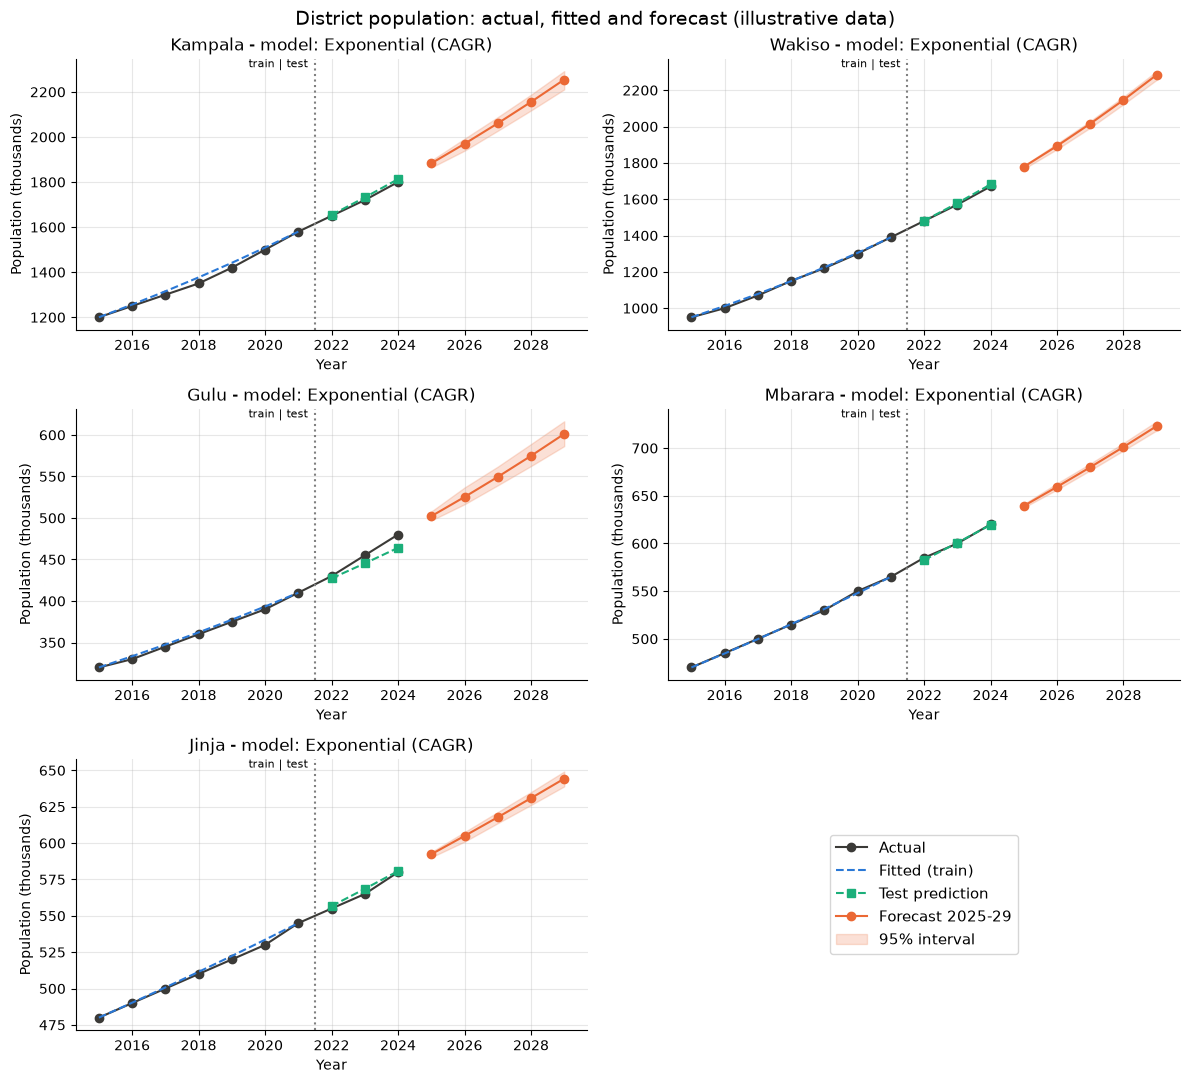

In [11]:
# Extension (used in the chart): 95% prediction intervals by bootstrapping residuals
intervals = {}
for name, district in districts.items():
    lower, upper = bootstrap_intervals(final_models[name], district.populations,
                                       HORIZON, n_resamples=1000, seed=SEED)
    intervals[name] = (lower, upper)

# plt.subplots(rows, columns) makes a grid of small charts ("axes")
fig, axes = plt.subplots(3, 2, figsize=(12, 11))
axes = axes.flatten()          # turn the 3x2 grid into a simple list of 6 axes

for ax, (name, district) in zip(axes, districts.items()):
    # 1) the model trained on 2015-2021 only: its fitted line and its test predictions
    train_years, train_values, test_years, test_values = district.split(TRAIN_END)
    model_name = best_models[name]
    validation_model = best_model_for(district, TRAIN_END).fit(train_years, train_values)
    test_guess = validation_model.predict(len(test_years))

    ax.plot(district.years, district.populations, "o-", color=INK, label="Actual")
    ax.plot(train_years, validation_model.fitted_values, "--", color=BLUE, label="Fitted (train)")
    ax.plot(test_years, test_guess, "s--", color=AQUA, label="Test prediction")

    # 2) the forecast from the model re-trained on all years, with its 95% band
    lower, upper = intervals[name]
    ax.plot(future_years, forecasts[name], "o-", color=ORANGE, label="Forecast 2025-29")
    ax.fill_between(future_years, lower, upper, color=ORANGE, alpha=0.2, label="95% interval")

    ax.axvline(TRAIN_END + 0.5, color="grey", linestyle=":")          # the split
    ax.text(TRAIN_END + 0.4, ax.get_ylim()[1], "train | test ", ha="right", va="top", fontsize=8)
    ax.set_title(f"{name} - model: {model_name}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Population (thousands)")

axes[-1].axis("off")                                                  # 6th panel unused
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc="center", fontsize=11)          # legend in empty panel
fig.suptitle("District population: actual, fitted and forecast (illustrative data)", fontsize=14)
fig.tight_layout()
plt.show()

## Task 8 – Planning output: extra classrooms by 2029

Assumptions from the brief: **18%** of people are of primary-school age, and one classroom holds **53** pupils.

Extra classrooms = (population 2029 − population 2024) × 1,000 × 0.18 ÷ 53, **rounded up**
(a partly-full class still needs a room).

In [12]:
planning_rows = []
for name, district in districts.items():
    now = district.populations[-1]        # 2024, thousands
    future = forecasts[name][-1]          # 2029 forecast, thousands
    planning_rows.append({
        "district": name,
        "population 2024 (k)": now,
        "forecast 2029 (k)": round(future, 1),
        "extra pupils": round((future - now) * 1000 * 0.18),
        "extra classrooms": extra_classrooms_needed(now, future),
    })
planning_table = pd.DataFrame(planning_rows).set_index("district")
planning_table

,population 2024 (k),forecast 2029 (k),extra pupils,extra classrooms
district,,,,
Kampala,1800.0,2254.8,81857,1545
Wakiso,1670.0,2284.7,110641,2088
Gulu,480.0,601.3,21829,412
Mbarara,620.0,723.1,18565,351
Jinja,580.0,644.3,11574,219


## Extension

### (a) 95% prediction intervals by bootstrap of residuals
Already shaded on the chart above. Method: the **residuals** (actual − fitted) are the model's past mistakes.
We imagine 1,000 possible futures. In each one, every forecast year adds a randomly chosen past mistake, and the
mistakes pile up, so later years are less certain. Then we keep the middle 95% of those futures (seeded, so it is
reproducible).

In [13]:
interval_rows = []
for name in districts:
    lower, upper = intervals[name]
    interval_rows.append({"district": name, "forecast 2029": forecasts[name][-1],
                          "95% low": lower[-1], "95% high": upper[-1]})
pd.DataFrame(interval_rows).set_index("district").round(0)

,forecast 2029,95% low,95% high
district,,,
Kampala,2255.0,2211.0,2292.0
Wakiso,2285.0,2257.0,2305.0
Gulu,601.0,587.0,616.0
Mbarara,723.0,719.0,728.0
Jinja,644.0,639.0,649.0


*Limitation of this simple bootstrap:* it only knows the 10 past mistakes of a very smooth illustrative series, and
it assumes the growth rate itself will not change. A shock (a new city boundary, a census revision, mass migration)
lies outside anything in the residuals, so the true uncertainty is wider than the band shows.

### (b) Critical assessment of the Fibonacci-ratio model

In [14]:
from src.population import fibonacci_ratios   # the ratios 1, 2, 1.5, 1.667, 1.6, ...

ratios = fibonacci_ratios(HORIZON)
print("Ratios used for 2025-2029:", np.round(ratios, 3))
print("Total growth multiplier over 5 years: x", round(float(np.prod(ratios)), 1))
print("Long-run ratio (golden ratio): ", round((1 + 5 ** 0.5) / 2, 3), "-> about 62% growth per year")
print("Actual CAGR of the districts:  ", ", ".join(f"{n} {d.cagr()*100:.1f}%" for n, d in districts.items()))

Ratios used for 2025-2029: [1.    2.    1.5   1.667 1.6  ]
Total growth multiplier over 5 years: x 8.0
Long-run ratio (golden ratio):  1.618 -> about 62% growth per year
Actual CAGR of the districts:   Kampala 4.6%, Wakiso 6.5%, Gulu 4.6%, Mbarara 3.1%, Jinja 2.1%


The Fibonacci model says every district will be **8 times bigger in five years** and will then keep growing by about
**62% per year**. Real district growth is 2–6% per year. The model is defensible only if a population
genuinely grows at ~60% a year, which no human population does. (Fibonacci's own example was rabbits with unlimited
food and no deaths.) Its multipliers come from a number sequence, not from births, deaths or migration, and it ignores the
data completely except for the last value. The test errors confirm it: its MAPE is about 80%, against under 5% for the other two models.
It should not be used for planning.

## Findings & Limitations

**Findings.** The exponential (CAGR) model won in all five districts, with test errors under 2.1% (MAPE), while the
straight line missed by up to 4%. The reason is visible in the growth table: each district grows by a roughly constant
*percentage*, so the yearly increase in people gets bigger every year. A straight line assumes a constant *number* of
extra people a year, so it falls further behind. For Kampala it predicted 1,749k for 2024 against an actual 1,800k.

Wakiso grows fastest in relative terms (6.5% a year), which is consistent with Kampala's population spilling over into
its neighbour. Jinja grows slowest (2.1%). This matters more than current size: **Wakiso needs about 2,090 extra
classrooms by 2029, more than Kampala (about 1,550)** even though it is smaller today. Across the five districts that
is over 4,600 classrooms in five years, roughly 920 a year. For a planning unit, the headline is that
classroom investment should follow *growth rates*, not current population.

The Fibonacci model was off by 78–92%, confirming that it is unusable.

**Limitations.** The data is illustrative and unusually smooth, so the models look more accurate than they would on
real UBOS estimates. Model selection rests on only three test years. CAGR assumes today's growth rate continues
unchanged. Compounding makes that assumption more dangerous the further ahead we look, and growth usually slows as
districts urbanise. The 18% school-age share and 53 pupils per classroom are fixed assumptions. The classroom estimate
ignores existing spare capacity, private schools and drop-out, so it is an upper bound on new public classrooms.
The bootstrap intervals only reflect past wiggles in smooth data and can't anticipate shocks such as boundary
changes or census revisions, so the real uncertainty is wider.